# Create DataBase

### Create bremer database

In [ ]:
CREATE DATABASE IF NOT EXISTS Bremer CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci;
USE Bremer;
 
SET NAMES utf8mb4;

### Create Tables

In [ ]:
SET FOREIGN_KEY_CHECKS = 0;
DROP TABLE IF EXISTS order_items;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS menu_items;
DROP TABLE IF EXISTS categories;
DROP TABLE IF EXISTS customers;
DROP TABLE IF EXISTS users;
SET FOREIGN_KEY_CHECKS = 1;

create categories tabele

In [ ]:
CREATE TABLE categories (
  category_id      INT AUTO_INCREMENT PRIMARY KEY,
  category_name    VARCHAR(100) NOT NULL,
  category_name_ar VARCHAR(100) NULL
);


create menu items table

In [ ]:
CREATE TABLE menu_items (
  item_id          INT AUTO_INCREMENT PRIMARY KEY,
  category_id      INT NOT NULL,
  item_name        VARCHAR(150) NOT NULL,
  item_name_ar     VARCHAR(150) NOT NULL,
  synonyms         TEXT NULL,
  price            DECIMAL(10,2) NOT NULL,
  is_available     BOOLEAN NOT NULL DEFAULT TRUE,
  description      TEXT NULL,
  description_ar   TEXT NULL,
  FOREIGN KEY (category_id) REFERENCES categories(category_id)
);

create customers table

In [ ]:
CREATE TABLE customers (
  customer_id   INT AUTO_INCREMENT PRIMARY KEY,
  customer_name VARCHAR(100) NULL,
  phone         VARCHAR(20) UNIQUE NULL,
  address       TEXT NULL,
  created_at    DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP
);

create orders table

In [ ]:
CREATE TABLE orders (
  order_id          INT AUTO_INCREMENT PRIMARY KEY,
  customer_id       INT NULL,
  order_date        DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP,
  status            ENUM('pending', 'confirmed', 'preparing', 'completed', 'cancelled') NOT NULL DEFAULT 'pending',
  order_source      ENUM('voice', 'pos', 'web_app') NOT NULL DEFAULT 'voice',
  raw_transcription TEXT NULL,
  confidence_score  DECIMAL(5,2) NULL,
  total_amount      DECIMAL(10,2) NOT NULL DEFAULT 0.00,
  FOREIGN KEY (customer_id) REFERENCES customers(customer_id)
);

create order items table

In [ ]:
CREATE TABLE order_items (
  order_item_id        INT AUTO_INCREMENT PRIMARY KEY,
  order_id             INT NOT NULL,
  item_id              INT NOT NULL,
  quantity             INT NOT NULL DEFAULT 1,
  unit_price           DECIMAL(10,2) NOT NULL,
  special_instructions TEXT NULL,
  FOREIGN KEY (order_id) REFERENCES orders(order_id) ON DELETE CASCADE,
  FOREIGN KEY (item_id)  REFERENCES menu_items(item_id)
);

create users table

In [ ]:
CREATE TABLE IF NOT EXISTS users (
  user_id       INT AUTO_INCREMENT PRIMARY KEY,
  username      VARCHAR(50) NOT NULL UNIQUE,
  password_hash VARCHAR(255) NOT NULL,
  role          ENUM('customer', 'chef', 'cashier', 'manager', 'system_ai') NOT NULL DEFAULT 'customer',
  pin_code      VARCHAR(10) NULL,
  full_name     VARCHAR(100) NULL,
  is_active     BOOLEAN NOT NULL DEFAULT TRUE,
  created_at    DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP
);

<br>

# EER Diagram

![DataBase EER Diagram.png](<attachment:DataBase EER Diagram.png>)
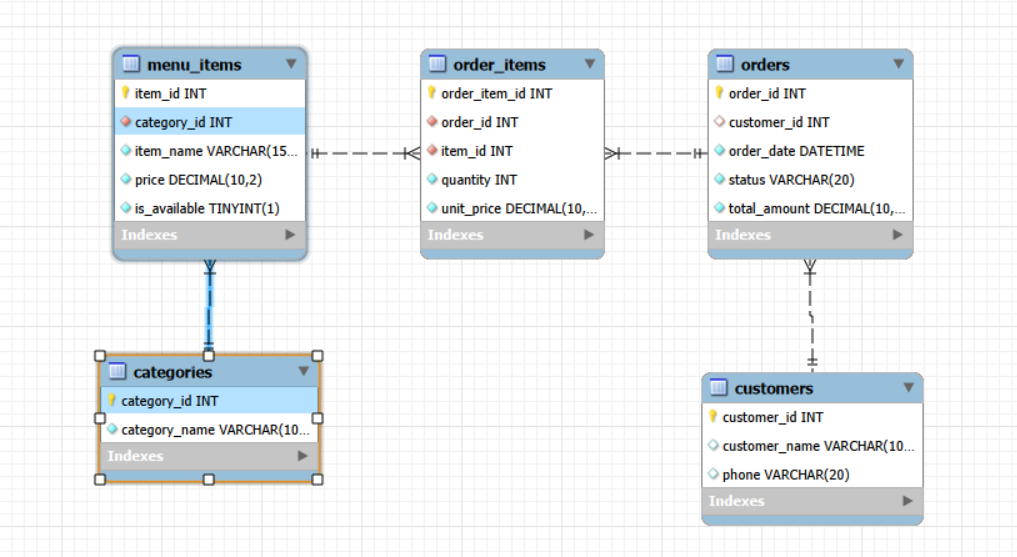

<br>

### Insert dataset to tables

`Category`

In [ ]:
INSERT INTO categories (category_id, category_name, category_name_ar) VALUES
(1, 'Appetizers', 'مقبلات'),
(2, 'Salads', 'سلطات'),
(3, 'Pasta', 'مكرونة (باستا)'),
(4, 'Asian Dishes', 'أطباق آسيوية'),
(5, 'Main Dishes', 'أطباق رئيسية'),
(6, 'Buns', 'برجر'),
(7, 'Rice Dishes', 'أطباق الأرز'),
(8, 'Oriental Meals', 'وجبات شرقية'),
(9, 'Sandwiches', 'ساندوتشات'),
(10, 'Pizza', 'بيتزا'),
(11, 'Side Dishes', 'أطباق جانبية'),
(12, 'Desserts', 'حلويات'),
(13, 'Shakes', 'ميلك شيك'),
(14, 'Soft Ice Cream', 'آيس كريم سوفت'),
(15, 'Cold Drinks', 'مشروبات باردة'),
(16, 'Iced Coffee', 'قهوة مثلجة'),
(17, 'Hot Coffee', 'قهوة ساخنة');

`Menu Items`

In [ ]:
INSERT INTO menu_items (item_id, category_id, item_name, item_name_ar, synonyms, price, is_available, description, description_ar) VALUES
(1, 1, 'Buffalo Wings', 'بافلو وينجز', 'وينجز,أجنحة بافلو,أجنحة دجاج,بافلو وينجز', 145.00, TRUE, 'Crispy chicken wings tossed in a tangy, spicy buffalo sauce.', 'أجنحة دجاج مقرمشة متبلة بصوص بافلو الحار والمنعش.'),
(2, 1, 'Burger Rolls (4 pcs)', 'برجر رولز (٤ قطع)', 'برجر رولز,رولز برجر,رولز ٤,رولز اربعة,اربع قطع رولز', 205.00, TRUE, 'Four golden fried rolls with a savory burger-style filling, perfect for starting a meal.', 'أربع قطع رولز ذهبية مقلية بحشو لذيذ بطعم البرجر، بداية مثالية للوجبة.'),
(3, 1, 'Burger Rolls (6 pcs)', 'برجر رولز (٦ قطع)', 'رولز ٦,رولز ستة,ست قطع رولز,برجر رولز كبير', 270.00, TRUE, 'Six golden fried rolls with a savory burger-style filling, great for sharing.', 'ست قطع رولز ذهبية مقلية بحشو لذيذ بطعم البرجر، مناسبة للمشاركة.'),
(4, 1, 'BR Fries', 'بي آر فرايز', 'بطاطس بي ار,بي ار فرايز,بطاطس بالصوص', 135.00, TRUE, 'Crispy fries finished with our signature BR seasoning and sauce.', 'بطاطس مقرمشة بتتبيلة وصوص بي آر المميز.'),
(5, 1, 'Texas Fries', 'تكساس فرايز', 'بطاطس تكساس,تكساس فرايز', 125.00, TRUE, 'Crispy fries with bold Texas-style toppings and sauce.', 'بطاطس مقرمشة بإضافات وصوص على الطريقة التكساسية.'),
(6, 1, 'Chicken Quesadillas', 'كيساديا دجاج', 'كساديا,كيساديلا,كيساديا فراخ,كساديا فراخ', 170.00, TRUE, 'Grilled tortillas filled with seasoned chicken and melted cheese.', 'خبز التورتيلا المشوي محشو بالدجاج المتبل والجبنة الذائبة.'),
(7, 1, 'Cheesy Nachos', 'ناتشوز بالجبنة', 'ناتشوز,ناتشوس,ناتشوز جبنة', 119.00, TRUE, 'Crunchy tortilla chips covered in warm, melted cheese sauce.', 'رقائق التورتيلا المقرمشة مغطاة بصوص الجبنة الدافئ.'),
(8, 1, 'Corn Ribs', 'كورن ريبس', 'كورن ريبز,ريبس الذرة,ذرة ريبس', 120.00, TRUE, 'Crispy fried corn ribs tossed in savory seasoning.', 'ذرة مقلية مقرمشة مقطعة على شكل ريبس ومتبلة بتتبيلة لذيذة.'),
(9, 2, 'Thai Beef', 'سلطة تاي بيف', 'سلطة تاي,تاي بيف,سلطة لحمة تاي', 199.00, TRUE, 'Fresh salad with tender beef strips and a tangy Thai-style dressing.', 'سلطة طازجة بشرائح لحم بقري طرية وصوص تايلندي منعش.'),
(10, 2, 'Ranch BBQ Chicken', 'سلطة رانش باربكيو دجاج', 'سلطة رانش,رانش باربكيو,سلطة رانش فراخ', 175.00, TRUE, 'Crisp greens topped with BBQ chicken and creamy ranch dressing.', 'خس طازج مع دجاج باربكيو وصوص رانش كريمي.'),
(11, 2, 'Fatoush Salad', 'سلطة فتوش', 'فتوش,فتوش سلطة', 140.00, TRUE, 'Classic Levantine salad of fresh vegetables and crispy bread with a tangy dressing.', 'سلطة شامية كلاسيكية من خضار طازجة وخبز مقرمش بصوص منعش.'),
(12, 2, 'Chicken Caesar', 'سلطة سيزر دجاج', 'سيزر,سلطة سيزر,سيزر تشيكن,سيزر فراخ', 180.00, TRUE, 'Crisp romaine lettuce with chicken, croutons and creamy Caesar dressing.', 'خس رومين مقرمش مع الدجاج والتوست المقرمش وصوص سيزر الكريمي.'),
(13, 2, 'Mexican Chicken', 'سلطة دجاج مكسيكي', 'سلطة مكسيكان,مكسيكان تشيكن,دجاج مكسيكي', 185.00, TRUE, 'Fresh salad with seasoned chicken and Mexican-style flavors.', 'سلطة طازجة بدجاج متبل ونكهات مكسيكية.'),
(14, 3, 'White Nashville', 'وايت ناشفيل', 'مكرونة ناشفيل,باستا ناشفيل,وايت ناشفيل باستا', 285.00, TRUE, 'Creamy white-sauce pasta with spicy Nashville-style chicken.', 'مكرونة بصوص أبيض كريمي مع دجاج حار على طريقة ناشفيل.'),
(15, 3, 'Creamy Shrimp', 'جمبري كريمي', 'مكرونة جمبري,باستا جمبري,شرمب كريمي,جمبري بالكريمة', 480.00, TRUE, 'Pasta with juicy shrimp in a rich, creamy sauce.', 'مكرونة مع جمبري طازج بصوص كريمي غني.'),
(16, 3, 'Buffalo Chicken', 'مكرونة بافلو تشيكن', 'باستا بافلو,مكرونة بافلو,بافلو تشيكن باستا', 255.00, TRUE, 'Pasta with chicken in a spicy, tangy buffalo sauce.', 'مكرونة بالدجاج في صوص بافلو الحار.'),
(17, 3, 'Chicken Pomodoro', 'دجاج بومودورو', 'مكرونة بومودورو,باستا بومودورو,بومودورو', 215.00, TRUE, 'Pasta with chicken in a fresh, flavorful tomato sauce.', 'مكرونة بالدجاج في صوص طماطم طازج ولذيذ.'),
(18, 3, 'Creamy Tandoori', 'تندوري كريمي', 'مكرونة تندوري,باستا تندوري,تندوري كريمي', 275.00, TRUE, 'Creamy pasta with tandoori-spiced chicken.', 'مكرونة كريمي مع دجاج متبل على الطريقة التندوري.'),
(19, 3, 'Chicken Alfredo', 'دجاج ألفريدو', 'مكرونة الفريدو,باستا الفريدو,الفريدو,دجاج الفريدو', 225.00, TRUE, 'Pasta with chicken in a rich, creamy Alfredo sauce.', 'مكرونة بالدجاج في صوص ألفريدو الكريمي الغني.'),
(20, 3, 'Creamy Shish', 'شيش كريمي', 'مكرونة شيش,باستا شيش,شيش كريمي', 280.00, TRUE, 'Creamy pasta with shish tawook-style chicken.', 'مكرونة كريمي مع دجاج على طريقة الشيش طاووق.'),
(21, 4, 'Sweet & Sour', 'سويت آند ساور', 'سويت اند ساور,حلو وحامض,دجاج حلو وحامض', 265.00, TRUE, 'Asian-style stir-fry in a tangy sweet and sour sauce.', 'طبق آسيوي سوتيه بصوص حلو وحامض منعش.'),
(22, 4, 'Kung Pao Chicken', 'كونج باو دجاج', 'كونج باو,كونغ باو,كونغ باو فراخ', 250.00, TRUE, 'Stir-fried chicken in a savory, mildly spicy Kung Pao sauce.', 'دجاج سوتيه بصوص كونج باو اللذيذ والحار قليلاً.'),
(23, 4, 'Hong Kong Beef', 'هونج كونج بيف', 'هونج كونج,هونغ كونغ,لحم هونج كونج', 380.00, TRUE, 'Tender beef strips stir-fried in a rich Hong Kong-style sauce.', 'شرائح لحم بقري طرية سوتيه بصوص غني على طريقة هونج كونج.'),
(24, 4, 'Shrimps Masala', 'جمبري ماسالا', 'ماسالا جمبري,شرمب ماسالا,جمبري ماسالا', 460.00, TRUE, 'Juicy shrimp cooked in a spiced masala sauce.', 'جمبري طازج مطهو في صوص ماسالا متبل.'),
(25, 4, 'Chicken Tikka Masala', 'دجاج تيكا ماسالا', 'تيكا ماسالا,تكا ماسالا,تيكا', 285.00, TRUE, 'Tender chicken pieces in a creamy, spiced tomato masala sauce.', 'قطع دجاج طرية في صوص طماطم ماسالا كريمي ومتبل.'),
(26, 4, 'Butter Chicken', 'دجاج بالزبدة (باتر تشيكن)', 'باتر تشيكن,باتر تشكن,دجاج بالزبدة', 285.00, TRUE, 'Chicken in a smooth, buttery, mildly spiced tomato sauce.', 'دجاج في صوص طماطم ناعم بالزبدة وتتبيلة هادئة.'),
(27, 5, 'Cajun Chicken', 'كاجون تشيكن', 'كاجون,دجاج كاجون,كاجن تشيكن', 305.00, TRUE, 'Juicy chicken seasoned with bold Cajun spices.', 'دجاج عصاري متبل ببهارات الكاجون القوية.'),
(28, 5, 'Buffalo Crunchy', 'بافلو كرانشي', 'طبق بافلو كرانشي,بافلو كرانشي طبق رئيسي', 305.00, TRUE, 'Crispy chicken coated in tangy buffalo sauce.', 'دجاج مقرمش مغطى بصوص بافلو المنعش.'),
(29, 5, 'Chicken À La Crème', 'دجاج ألا كريم', 'الا كريم,دجاج بالكريمة,تشيكن الا كريم', 305.00, TRUE, 'Tender chicken in a rich, creamy sauce.', 'دجاج طري في صوص كريمي غني.'),
(30, 5, 'Steak', 'ستيك', 'ستيك لحم,ستيك بيف,استيك', 590.00, TRUE, 'Juicy grilled beef steak, our premium main dish.', 'ستيك لحم مشوي عصاري، طبقنا الفاخر.'),
(31, 5, 'Nashville Tenders', 'ناشفيل تندرز', 'تندرز,تندرز ناشفيل,ستربس ناشفيل', 280.00, TRUE, 'Crispy chicken tenders coated in spicy Nashville-style seasoning.', 'أصابع دجاج مقرمشة مغطاة بتتبيلة ناشفيل الحارة.'),
(32, 5, 'Smoked Cheesy', 'سموكد تشيزي', 'سموك تشيزي,سموكي تشيزي,دجاج مدخن بالجبنة', 290.00, TRUE, 'Crispy chicken with smoky flavor and melted cheese.', 'دجاج مقرمش بنكهة مدخنة وجبنة ذائبة.'),
(33, 5, 'Smoked Crunchy', 'سموكد كرانشي', 'سموك كرانشي,سموكي كرانشي,دجاج مدخن كرانشي', 299.00, TRUE, 'Crunchy chicken with a smoky seasoning.', 'دجاج مقرمش بتتبيلة مدخنة.'),
(34, 5, 'Crunchy Chicken', 'كرانشي تشيكن', 'دجاج كرانشي,فراخ كرانشي,كرانشي تشيكن', 240.00, TRUE, 'Golden, crispy fried chicken that is juicy on the inside.', 'دجاج مقلي ذهبي ومقرمش وعصاري من الداخل.'),
(35, 6, 'OG Burger', 'أو جي برجر', 'برجر,او جي,برجر اوجي,برجر لحم,او جي برجر', 270.00, TRUE, 'Our original burger: a juicy patty in a soft bun.', 'برجرنا الأصلي: قطعة لحم عصارية في خبز طري.'),
(36, 6, 'Buff Chicken', 'بَف تشيكن', 'بف تشيكن,برجر بافلو,برجر دجاج بافلو', 185.00, TRUE, 'Crispy chicken burger with tangy buffalo sauce.', 'برجر دجاج مقرمش بصوص بافلو المنعش.'),
(37, 6, 'Little Nashville', 'ليتل ناشفيل', 'ناشفيل صغير,برجر ناشفيل,ليتل ناشفيل', 165.00, TRUE, 'A smaller crispy chicken burger with spicy Nashville seasoning.', 'برجر دجاج مقرمش بحجم أصغر وتتبيلة ناشفيل الحارة.'),
(38, 6, 'Truffle Mushroom Burger', 'برجر ترافل مشروم', 'برجر ترافل,ترافل مشروم,برجر مشروم', 295.00, TRUE, 'Burger topped with sauteed mushrooms and an earthy truffle flavor.', 'برجر بالمشروم المحمّر ونكهة الترافل الغنية.'),
(39, 7, 'Tandoori Chicken (Rice Dish)', 'دجاج تندوري مع أرز', 'تندوري رايس,تندوري بالارز,فراخ تندوري رز', 235.00, TRUE, 'Tandoori-spiced chicken served over rice.', 'دجاج متبل بالتندوري يُقدم مع الأرز.'),
(40, 7, 'Grilled Kofta (Rice Dish)', 'كفتة مشوية مع أرز', 'كفتة رايس,كفتة بالارز,كفتة مشوية رز', 260.00, TRUE, 'Grilled seasoned kofta served with rice.', 'كفتة مشوية متبلة تُقدم مع الأرز.'),
(41, 7, 'Beef Stroganoff', 'بيف ستروجانوف', 'ستروجانوف,استروجانوف,بيف ستراجانوف', 399.00, TRUE, 'Tender beef strips in a rich, creamy sauce, served on rice.', 'شرائح لحم بقري طرية في صوص كريمي غني، تُقدم على الأرز.'),
(42, 7, 'Shish Tawook (Rice Dish)', 'شيش طاووق مع أرز', 'شيش طاووق رايس,شيش بالارز,طاووق رز', 220.00, TRUE, 'Marinated grilled shish tawook chicken served with rice.', 'دجاج شيش طاووق متبل ومشوي يُقدم مع الأرز.'),
(43, 8, 'Tandoori & Shish Meal', 'وجبة تندوري وشيش', 'تندوري وشيش,وجبة تندوري شيش', 290.00, TRUE, 'Grilled tandoori chicken and shish tawook served together as a full meal.', 'دجاج تندوري مشوي وشيش طاووق يُقدمان معاً كوجبة كاملة.'),
(44, 8, 'Shish Tawook & Kebab Meal', 'وجبة شيش طاووق وكباب', 'شيش طاووق وكباب,وجبة شيش وكباب', 380.00, TRUE, 'Grilled shish tawook with kebab, served as a full oriental meal.', 'شيش طاووق مشوي مع كباب، يُقدمان كوجبة شرقية كاملة.'),
(45, 8, 'Mix Grill (Breasts - Shish)', 'مشاوي مشكلة (صدور - شيش)', 'ميكس جريل,مشاوي مشكلة,ميكس جريل صدور', 385.00, TRUE, 'Assorted grill of chicken breasts and shish tawook.', 'مشاوي مشكلة من صدور الدجاج والشيش طاووق.'),
(46, 8, 'Kebab & Kofta', 'كباب وكفتة', 'كباب كفتة,وجبة كباب وكفتة', 430.00, TRUE, 'A grilled platter of kebab and kofta.', 'طبق مشاوي من الكباب والكفتة.'),
(47, 8, 'Tandoori Chicken (Oriental Meal)', 'وجبة دجاج تندوري', 'وجبة تندوري,تندوري وجبة,وجبة فراخ تندوري', 290.00, TRUE, 'Tandoori-marinated chicken, grilled and served as a full meal.', 'دجاج متبل بالتندوري، مشوي ويُقدم كوجبة كاملة.'),
(48, 8, 'Chicken Breasts', 'صدور دجاج', 'صدور فراخ,وجبة صدور,صدور', 285.00, TRUE, 'Grilled chicken breasts served as a full oriental meal.', 'صدور دجاج مشوية تُقدم كوجبة شرقية كاملة.'),
(49, 8, 'Grilled Kofta (Oriental Meal)', 'وجبة كفتة مشوية', 'وجبة كفتة,كفتة وجبة,كفتة مشوية وجبة', 375.00, TRUE, 'Grilled seasoned kofta served as a full oriental meal.', 'كفتة مشوية متبلة تُقدم كوجبة شرقية كاملة.'),
(50, 8, 'Tandoori Mix Grill', 'ميكس جريل تندوري', 'ميكس تندوري,مشاوي تندوري,تندوري ميكس جريل', 465.00, TRUE, 'A generous mixed grill of tandoori-marinated meats.', 'مشاوي مشكلة كبيرة من اللحوم المتبلة بالتندوري.'),
(51, 9, 'Sweet Chili Crunchy Sandwich (Large)', 'ساندوتش سويت تشيلي كرانشي (لارج)', 'سندوتش سويت تشيلي لارج,سندوتش سويت تشيلي كبير,سندوتش سويت تشيلي كرانشي لارج,سندوتش سويت تشيلي كرانشي كبير', 160.00, TRUE, 'Crispy chicken with sweet chili sauce, served in a large sandwich.', 'دجاج مقرمش بصوص سويت تشيلي، يُقدم في ساندوتش كبير.'),
(52, 9, 'Sweet Chili Crunchy Sandwich (Baguette)', 'ساندوتش سويت تشيلي كرانشي (باجيت)', 'سندوتش سويت تشيلي باجيت,سندوتش سويت تشيلي باغيت,سندوتش سويت تشيلي كرانشي باجيت,سندوتش سويت تشيلي كرانشي باغيت', 199.00, TRUE, 'Crispy chicken with sweet chili sauce, served in a crusty baguette.', 'دجاج مقرمش بصوص سويت تشيلي، يُقدم في خبز باجيت مقرمش.'),
(53, 9, 'Cordon Bleu Sandwich (Large)', 'ساندوتش كوردون بلو (لارج)', 'سندوتش كوردون بلو لارج,سندوتش كوردون بلو كبير,سندوتش كوردن بلو لارج,سندوتش كوردن بلو كبير', 160.00, TRUE, 'Crispy cordon bleu chicken with melted cheese, served in a large sandwich.', 'دجاج كوردون بلو مقرمش مع الجبنة الذائبة، يُقدم في ساندوتش كبير.'),
(54, 9, 'Cordon Bleu Sandwich (Baguette)', 'ساندوتش كوردون بلو (باجيت)', 'سندوتش كوردون بلو باجيت,سندوتش كوردون بلو باغيت,سندوتش كوردن بلو باجيت,سندوتش كوردن بلو باغيت', 195.00, TRUE, 'Crispy cordon bleu chicken with melted cheese, served in a crusty baguette.', 'دجاج كوردون بلو مقرمش مع الجبنة الذائبة، يُقدم في خبز باجيت مقرمش.'),
(55, 9, 'Crispy Smoky Sandwich (Large)', 'ساندوتش كريسبي سموكي (لارج)', 'سندوتش كريسبي سموكي لارج,سندوتش كريسبي سموكي كبير,سندوتش كريسبي سموك لارج,سندوتش كريسبي سموك كبير', 185.00, TRUE, 'Crispy chicken with smoky sauce, served in a large sandwich.', 'دجاج مقرمش بصوص سموكي، يُقدم في ساندوتش كبير.'),
(56, 9, 'Crispy Smoky Sandwich (Baguette)', 'ساندوتش كريسبي سموكي (باجيت)', 'سندوتش كريسبي سموكي باجيت,سندوتش كريسبي سموكي باغيت,سندوتش كريسبي سموك باجيت,سندوتش كريسبي سموك باغيت', 225.00, TRUE, 'Crispy chicken with smoky sauce, served in a crusty baguette.', 'دجاج مقرمش بصوص سموكي، يُقدم في خبز باجيت مقرمش.'),
(57, 9, 'Shish Tawook Sandwich (Large)', 'ساندوتش شيش طاووق (لارج)', 'سندوتش شيش طاووق لارج,سندوتش شيش طاووق كبير,سندوتش شيش لارج,سندوتش شيش كبير', 155.00, TRUE, 'Marinated grilled shish tawook chicken, served in a large sandwich.', 'دجاج شيش طاووق متبل ومشوي، يُقدم في ساندوتش كبير.'),
(58, 9, 'Shish Tawook Sandwich (Baguette)', 'ساندوتش شيش طاووق (باجيت)', 'سندوتش شيش طاووق باجيت,سندوتش شيش طاووق باغيت,سندوتش شيش باجيت,سندوتش شيش باغيت', 190.00, TRUE, 'Marinated grilled shish tawook chicken, served in a crusty baguette.', 'دجاج شيش طاووق متبل ومشوي، يُقدم في خبز باجيت مقرمش.'),
(59, 9, 'Buffalo Crunchy Sandwich (Large)', 'ساندوتش بافلو كرانشي (لارج)', 'سندوتش بافلو كرانشي لارج,سندوتش بافلو كرانشي كبير,سندوتش بافلو لارج,سندوتش بافلو كبير', 185.00, TRUE, 'Crispy chicken tossed in buffalo sauce, served in a large sandwich.', 'دجاج مقرمش مغطى بصوص بافلو، يُقدم في ساندوتش كبير.'),
(60, 9, 'Buffalo Crunchy Sandwich (Baguette)', 'ساندوتش بافلو كرانشي (باجيت)', 'سندوتش بافلو كرانشي باجيت,سندوتش بافلو كرانشي باغيت,سندوتش بافلو باجيت,سندوتش بافلو باغيت', 225.00, TRUE, 'Crispy chicken tossed in buffalo sauce, served in a crusty baguette.', 'دجاج مقرمش مغطى بصوص بافلو، يُقدم في خبز باجيت مقرمش.'),
(61, 9, 'Grilled Chicken Sandwich (Large)', 'ساندوتش دجاج مشوي (لارج)', 'سندوتش جريلد تشيكن لارج,سندوتش جريلد تشيكن كبير,سندوتش دجاج مشوي لارج,سندوتش دجاج مشوي كبير,سندوتش فراخ مشوية لارج,سندوتش فراخ مشوية كبير', 160.00, TRUE, 'Juicy grilled chicken, served in a large sandwich.', 'دجاج مشوي عصاري، يُقدم في ساندوتش كبير.'),
(62, 9, 'Grilled Chicken Sandwich (Baguette)', 'ساندوتش دجاج مشوي (باجيت)', 'سندوتش جريلد تشيكن باجيت,سندوتش جريلد تشيكن باغيت,سندوتش دجاج مشوي باجيت,سندوتش دجاج مشوي باغيت,سندوتش فراخ مشوية باجيت,سندوتش فراخ مشوية باغيت', 195.00, TRUE, 'Juicy grilled chicken, served in a crusty baguette.', 'دجاج مشوي عصاري، يُقدم في خبز باجيت مقرمش.'),
(63, 9, 'Tandoori Chicken Sandwich (Large)', 'ساندوتش دجاج تندوري (لارج)', 'سندوتش تندوري لارج,سندوتش تندوري كبير,سندوتش دجاج تندوري لارج,سندوتش دجاج تندوري كبير,سندوتش فراخ تندوري لارج,سندوتش فراخ تندوري كبير', 170.00, TRUE, 'Tandoori-spiced chicken, served in a large sandwich.', 'دجاج متبل بالتندوري، يُقدم في ساندوتش كبير.'),
(64, 9, 'Tandoori Chicken Sandwich (Baguette)', 'ساندوتش دجاج تندوري (باجيت)', 'سندوتش تندوري باجيت,سندوتش تندوري باغيت,سندوتش دجاج تندوري باجيت,سندوتش دجاج تندوري باغيت,سندوتش فراخ تندوري باجيت,سندوتش فراخ تندوري باغيت', 210.00, TRUE, 'Tandoori-spiced chicken, served in a crusty baguette.', 'دجاج متبل بالتندوري، يُقدم في خبز باجيت مقرمش.'),
(65, 9, 'Grilled Kofta Sandwich (Large)', 'ساندوتش كفتة مشوية (لارج)', 'سندوتش كفتة لارج,سندوتش كفتة كبير,سندوتش كفتة مشوية لارج,سندوتش كفتة مشوية كبير', 165.00, TRUE, 'Grilled seasoned kofta, served in a large sandwich.', 'كفتة مشوية متبلة، يُقدم في ساندوتش كبير.'),
(66, 9, 'Grilled Kofta Sandwich (Baguette)', 'ساندوتش كفتة مشوية (باجيت)', 'سندوتش كفتة باجيت,سندوتش كفتة باغيت,سندوتش كفتة مشوية باجيت,سندوتش كفتة مشوية باغيت', 205.00, TRUE, 'Grilled seasoned kofta, served in a crusty baguette.', 'كفتة مشوية متبلة، يُقدم في خبز باجيت مقرمش.'),
(67, 9, 'Philly Cheese Steak Sandwich (Large)', 'ساندوتش فيلي تشيز ستيك (لارج)', 'سندوتش فيلي تشيز ستيك,سندوتش فيلي ستيك,سندوتش فيلي,فيلي تشيز ستيك', 310.00, TRUE, 'Thinly sliced steak with melted cheese, served in a large sandwich.', 'شرائح ستيك رفيعة مع جبنة ذائبة، تُقدم في ساندوتش كبير.'),
(68, 10, 'Tandoori Chicken Ranch Pizza (Medium)', 'بيتزا دجاج تندوري رانش (وسط)', 'بيتزا تندوري رانش وسط,بيتزا تندوري رانش ميديم,بيتزا دجاج تندوري رانش وسط,بيتزا دجاج تندوري رانش ميديم', 250.00, TRUE, 'Tandoori-spiced chicken with creamy ranch sauce and melted cheese. Medium size.', 'دجاج متبل بالتندوري مع صوص رانش كريمي وجبنة ذائبة. حجم وسط.'),
(69, 10, 'Tandoori Chicken Ranch Pizza (Large)', 'بيتزا دجاج تندوري رانش (كبير)', 'بيتزا تندوري رانش كبير,بيتزا تندوري رانش لارج,بيتزا دجاج تندوري رانش كبير,بيتزا دجاج تندوري رانش لارج', 295.00, TRUE, 'Tandoori-spiced chicken with creamy ranch sauce and melted cheese. Large size.', 'دجاج متبل بالتندوري مع صوص رانش كريمي وجبنة ذائبة. حجم كبير.'),
(70, 10, 'Cheese Lovers Pizza (Medium)', 'بيتزا تشيز لوفرز (وسط)', 'بيتزا تشيز لوفرز وسط,بيتزا تشيز لوفرز ميديم,بيتزا تشيز لافرز وسط,بيتزا تشيز لافرز ميديم', 200.00, TRUE, 'A cheese-packed pizza with plenty of melted cheese. Medium size.', 'بيتزا محشوة بكمية كبيرة من الجبنة الذائبة. حجم وسط.'),
(71, 10, 'Cheese Lovers Pizza (Large)', 'بيتزا تشيز لوفرز (كبير)', 'بيتزا تشيز لوفرز كبير,بيتزا تشيز لوفرز لارج,بيتزا تشيز لافرز كبير,بيتزا تشيز لافرز لارج', 235.00, TRUE, 'A cheese-packed pizza with plenty of melted cheese. Large size.', 'بيتزا محشوة بكمية كبيرة من الجبنة الذائبة. حجم كبير.'),
(72, 10, 'Quattro Formaggi Pizza (Medium)', 'بيتزا كواترو فورماجي (وسط)', 'بيتزا كواترو فورماجي وسط,بيتزا كواترو فورماجي ميديم,بيتزا اربع جبن وسط,بيتزا اربع جبن ميديم,بيتزا فورماجي وسط,بيتزا فورماجي ميديم', 215.00, TRUE, 'A four-cheese pizza. Medium size.', 'بيتزا بأربعة أنواع من الجبن. حجم وسط.'),
(73, 10, 'Quattro Formaggi Pizza (Large)', 'بيتزا كواترو فورماجي (كبير)', 'بيتزا كواترو فورماجي كبير,بيتزا كواترو فورماجي لارج,بيتزا اربع جبن كبير,بيتزا اربع جبن لارج,بيتزا فورماجي كبير,بيتزا فورماجي لارج', 250.00, TRUE, 'A four-cheese pizza. Large size.', 'بيتزا بأربعة أنواع من الجبن. حجم كبير.'),
(74, 10, 'Cheesy Pepperoni Pizza (Medium)', 'بيتزا تشيزي بيبروني (وسط)', 'بيتزا تشيزي بيبروني وسط,بيتزا تشيزي بيبروني ميديم,بيتزا بيبروني وسط,بيتزا بيبروني ميديم,بيتزا ببروني وسط,بيتزا ببروني ميديم', 235.00, TRUE, 'Pepperoni with extra melted cheese. Medium size.', 'بيبروني مع جبنة إضافية ذائبة. حجم وسط.'),
(75, 10, 'Cheesy Pepperoni Pizza (Large)', 'بيتزا تشيزي بيبروني (كبير)', 'بيتزا تشيزي بيبروني كبير,بيتزا تشيزي بيبروني لارج,بيتزا بيبروني كبير,بيتزا بيبروني لارج,بيتزا ببروني كبير,بيتزا ببروني لارج', 265.00, TRUE, 'Pepperoni with extra melted cheese. Large size.', 'بيبروني مع جبنة إضافية ذائبة. حجم كبير.'),
(76, 10, 'Vegetarian Pizza (Medium)', 'بيتزا خضار (وسط)', 'بيتزا خضار وسط,بيتزا خضار ميديم,بيتزا فيجيتاريان وسط,بيتزا فيجيتاريان ميديم,بيتزا خضروات وسط,بيتزا خضروات ميديم', 180.00, TRUE, 'Fresh vegetables with melted cheese. Medium size.', 'خضار طازجة مع جبنة ذائبة. حجم وسط.'),
(77, 10, 'Vegetarian Pizza (Large)', 'بيتزا خضار (كبير)', 'بيتزا خضار كبير,بيتزا خضار لارج,بيتزا فيجيتاريان كبير,بيتزا فيجيتاريان لارج,بيتزا خضروات كبير,بيتزا خضروات لارج', 210.00, TRUE, 'Fresh vegetables with melted cheese. Large size.', 'خضار طازجة مع جبنة ذائبة. حجم كبير.'),
(78, 10, 'BR Pizza (Medium)', 'بيتزا بي آر (وسط)', 'بيتزا بي ار وسط,بيتزا بي ار ميديم', 255.00, TRUE, 'The house signature pizza with a generous mix of toppings. Medium size.', 'بيتزا المطعم المميزة بمزيج سخي من الإضافات. حجم وسط.'),
(79, 10, 'BR Pizza (Large)', 'بيتزا بي آر (كبير)', 'بيتزا بي ار كبير,بيتزا بي ار لارج', 295.00, TRUE, 'The house signature pizza with a generous mix of toppings. Large size.', 'بيتزا المطعم المميزة بمزيج سخي من الإضافات. حجم كبير.'),
(80, 10, 'Special Quattro Pizza (Medium)', 'بيتزا سبيشال كواترو (وسط)', 'بيتزا سبيشال كواترو وسط,بيتزا سبيشال كواترو ميديم,بيتزا سبيشيال كواترو وسط,بيتزا سبيشيال كواترو ميديم', 240.00, TRUE, 'A specialty pizza with a mix of four topping styles. Medium size.', 'بيتزا خاصة بمزيج من أربع إضافات. حجم وسط.'),
(81, 10, 'Special Quattro Pizza (Large)', 'بيتزا سبيشال كواترو (كبير)', 'بيتزا سبيشال كواترو كبير,بيتزا سبيشال كواترو لارج,بيتزا سبيشيال كواترو كبير,بيتزا سبيشيال كواترو لارج', 265.00, TRUE, 'A specialty pizza with a mix of four topping styles. Large size.', 'بيتزا خاصة بمزيج من أربع إضافات. حجم كبير.'),
(82, 10, 'Cheesy Supreme Pizza (Medium)', 'بيتزا تشيزي سوبريم (وسط)', 'بيتزا تشيزي سوبريم وسط,بيتزا تشيزي سوبريم ميديم', 245.00, TRUE, 'A loaded supreme pizza with extra cheese. Medium size.', 'بيتزا سوبريم محملة بالإضافات مع جبنة زيادة. حجم وسط.'),
(83, 10, 'Cheesy Supreme Pizza (Large)', 'بيتزا تشيزي سوبريم (كبير)', 'بيتزا تشيزي سوبريم كبير,بيتزا تشيزي سوبريم لارج', 290.00, TRUE, 'A loaded supreme pizza with extra cheese. Large size.', 'بيتزا سوبريم محملة بالإضافات مع جبنة زيادة. حجم كبير.'),
(84, 10, 'Chicken Pizza (Medium)', 'بيتزا دجاج (وسط)', 'بيتزا دجاج وسط,بيتزا دجاج ميديم,بيتزا فراخ وسط,بيتزا فراخ ميديم,بيتزا تشيكن وسط,بيتزا تشيكن ميديم', 230.00, TRUE, 'Chicken pieces with melted cheese. Medium size.', 'قطع دجاج مع جبنة ذائبة. حجم وسط.'),
(85, 10, 'Chicken Pizza (Large)', 'بيتزا دجاج (كبير)', 'بيتزا دجاج كبير,بيتزا دجاج لارج,بيتزا فراخ كبير,بيتزا فراخ لارج,بيتزا تشيكن كبير,بيتزا تشيكن لارج', 270.00, TRUE, 'Chicken pieces with melted cheese. Large size.', 'قطع دجاج مع جبنة ذائبة. حجم كبير.'),
(86, 10, 'Tuna Pizza (Medium)', 'بيتزا تونة (وسط)', 'بيتزا تونة وسط,بيتزا تونة ميديم,بيتزا تونه وسط,بيتزا تونه ميديم', 205.00, TRUE, 'Tuna with melted cheese. Medium size.', 'تونة مع جبنة ذائبة. حجم وسط.'),
(87, 10, 'Tuna Pizza (Large)', 'بيتزا تونة (كبير)', 'بيتزا تونة كبير,بيتزا تونة لارج,بيتزا تونه كبير,بيتزا تونه لارج', 235.00, TRUE, 'Tuna with melted cheese. Large size.', 'تونة مع جبنة ذائبة. حجم كبير.'),
(88, 10, 'Super Supreme Pizza (Medium)', 'بيتزا سوبر سوبريم (وسط)', 'بيتزا سوبر سوبريم وسط,بيتزا سوبر سوبريم ميديم,بيتزا سوبر سبريم وسط,بيتزا سوبر سبريم ميديم', 235.00, TRUE, 'A fully loaded supreme pizza with a wide mix of toppings. Medium size.', 'بيتزا سوبريم محملة بمزيج واسع من الإضافات. حجم وسط.'),
(89, 10, 'Super Supreme Pizza (Large)', 'بيتزا سوبر سوبريم (كبير)', 'بيتزا سوبر سوبريم كبير,بيتزا سوبر سوبريم لارج,بيتزا سوبر سبريم كبير,بيتزا سوبر سبريم لارج', 280.00, TRUE, 'A fully loaded supreme pizza with a wide mix of toppings. Large size.', 'بيتزا سوبريم محملة بمزيج واسع من الإضافات. حجم كبير.'),
(90, 10, 'Chicken BBQ Pizza (Medium)', 'بيتزا دجاج باربكيو (وسط)', 'بيتزا دجاج باربكيو وسط,بيتزا دجاج باربكيو ميديم,بيتزا تشيكن باربكيو وسط,بيتزا تشيكن باربكيو ميديم,بيتزا فراخ باربكيو وسط,بيتزا فراخ باربكيو ميديم', 240.00, TRUE, 'Chicken with BBQ sauce and melted cheese. Medium size.', 'دجاج بصوص الباربكيو وجبنة ذائبة. حجم وسط.'),
(91, 10, 'Chicken BBQ Pizza (Large)', 'بيتزا دجاج باربكيو (كبير)', 'بيتزا دجاج باربكيو كبير,بيتزا دجاج باربكيو لارج,بيتزا تشيكن باربكيو كبير,بيتزا تشيكن باربكيو لارج,بيتزا فراخ باربكيو كبير,بيتزا فراخ باربكيو لارج', 275.00, TRUE, 'Chicken with BBQ sauce and melted cheese. Large size.', 'دجاج بصوص الباربكيو وجبنة ذائبة. حجم كبير.'),
(92, 11, 'Wings Combo', 'كومبو وينجز', 'وينجز كومبو,كومبو الأجنحة,كومبو اجنحة', 165.00, TRUE, 'Chicken wings combo served with sides.', 'كومبو أجنحة الدجاج يُقدم مع الإضافات.'),
(93, 11, 'French Fries', 'بطاطس مقلية', 'بطاطس,فرايز,بطاطس فرايز,french fries', 45.00, TRUE, 'Classic golden, crispy french fries.', 'بطاطس مقلية كلاسيكية ذهبية ومقرمشة.'),
(94, 11, 'Regular Combo', 'كومبو عادي', 'كومبو ريجولار,ريجولر كومبو,كومبو عادي', 65.00, TRUE, 'A regular combo side to complete your meal.', 'كومبو عادي لإكمال وجبتك.'),
(95, 11, 'Texas Combo', 'كومبو تكساس', 'تكساس كومبو', 145.00, TRUE, 'Texas fries combo to complete your meal.', 'كومبو بطاطس تكساس لإكمال وجبتك.'),
(96, 11, 'BR Combo', 'كومبو بي آر', 'بي ار كومبو', 155.00, TRUE, 'BR fries combo to complete your meal.', 'كومبو بطاطس بي آر لإكمال وجبتك.'),
(97, 11, 'Sweet Corn', 'ذرة حلوة', 'ذرة,درة,سويت كورن,كورن', 60.00, TRUE, 'Warm, sweet corn kernels.', 'حبات ذرة حلوة دافئة.'),
(98, 11, 'Small Rice', 'أرز صغير', 'رز,رز صغير,ارز,ارز ابيض', 50.00, TRUE, 'A small portion of fluffy rice.', 'حصة صغيرة من الأرز الطري.'),
(99, 11, 'Kashmiri Rice', 'أرز كشميري', 'رز كشميري,كشميري', 65.00, TRUE, 'Fragrant rice with a mildly sweet, aromatic Kashmiri-style flavor.', 'أرز عطري بنكهة كشميرية حلوة قليلاً.'),
(100, 11, 'Pasta (Side)', 'مكرونة (طبق جانبي)', 'مكرونة جانبي,باستا جانبي,مكرونة سايد', 75.00, TRUE, 'A small portion of pasta as a side.', 'حصة صغيرة من المكرونة كطبق جانبي.'),
(101, 11, 'Creamy Pasta (Side)', 'مكرونة كريمي (طبق جانبي)', 'مكرونة بالكريمة جانبي,باستا كريمي سايد,مكرونة كريمي سايد', 85.00, TRUE, 'A small portion of creamy pasta as a side.', 'حصة صغيرة من المكرونة الكريمي كطبق جانبي.'),
(102, 11, 'Noodles', 'نودلز', 'نودلس,نوديلز', 75.00, TRUE, 'Stir-fried noodles as a side.', 'نودلز سوتيه كطبق جانبي.'),
(103, 11, 'Mashed Potatoes', 'بطاطس مهروسة', 'بطاطس بوريه,بيوريه,هريس بطاطس', 50.00, TRUE, 'Smooth, creamy mashed potatoes.', 'بطاطس مهروسة ناعمة وكريمية.'),
(104, 11, 'Coleslaw', 'كولسلو', 'كول سلو,سلطة كولسلو,سلطة ملفوف', 55.00, TRUE, 'Cool, crunchy cabbage and carrot salad in a creamy dressing.', 'سلطة ملفوف وجزر باردة ومقرمشة بصوص كريمي.'),
(105, 11, 'Green Salad', 'سلطة خضراء', 'سلطة,سلطة خضرا,جرين سلاد', 50.00, TRUE, 'Fresh mixed green salad.', 'سلطة خضراء طازجة مشكلة.'),
(106, 11, 'Sauce', 'صوص', 'صوص زيادة,صلصة,علبة صوص', 16.00, TRUE, 'Extra dipping sauce.', 'صوص إضافي للتغميس.'),
(107, 11, 'Soft Drinks', 'مشروب غازي', 'كولا,بيبسي,كوكاكولا,سفن اب,مياه غازية,حاجة ساقعة', 35.00, TRUE, 'A chilled soft drink.', 'مشروب غازي مثلج.'),
(108, 11, 'Small Water', 'مياه صغيرة', 'مياه,ماء,ازازة مياه,مية', 20.00, TRUE, 'A small bottle of water.', 'زجاجة مياه صغيرة.'),
(109, 12, 'Chocolate Soufflé', 'سوفليه شوكولاتة', 'سوفليه,سوفلية,سوفلي شوكولاتة', 155.00, TRUE, 'Warm chocolate souffle with a soft, rich center.', 'سوفليه شوكولاتة دافئ بقلب طري وغني.'),
(110, 12, 'Molten Sticks', 'مولتن ستيكس', 'مولتن,أصابع شوكولاتة', 175.00, TRUE, 'Crispy sticks filled with warm, molten chocolate.', 'أصابع مقرمشة محشوة بالشوكولاتة الذائبة الدافئة.'),
(111, 12, 'Cookie Dough', 'كوكي دو', 'كوكيز,كوكي', 155.00, TRUE, 'Warm, gooey cookie dough dessert.', 'حلوى كوكي دو دافئة وطرية.'),
(112, 12, 'Chocolate Cheesecake', 'تشيز كيك شوكولاتة', 'تشيز كيك,تشيزكيك,تشيز كيك شوكولا', 140.00, TRUE, 'Creamy cheesecake with rich chocolate.', 'تشيز كيك كريمي بالشوكولاتة الغنية.'),
(113, 12, 'Bueno Cake', 'كيك بوينو', 'بوينو كيك,كيكة بوينو', 230.00, TRUE, 'Soft cake with creamy hazelnut-chocolate Bueno flavor.', 'كيكة طرية بنكهة البوينو الكريمية بالبندق والشوكولاتة.'),
(114, 12, 'Saltin'' Up', 'سولتين أب', 'سالتن اب,سولتن اب,سولتين اب', 240.00, TRUE, 'A signature sweet and salty dessert.', 'حلوى مميزة تجمع بين الحلو والمالح.'),
(115, 12, 'Tres Leches', 'تريس ليتشس', 'تريس ليش,تريليتشي,تريس ليتشيس', 170.00, TRUE, 'Soft sponge cake soaked in three kinds of milk.', 'كيكة إسفنجية طرية مغموسة في ثلاثة أنواع من الحليب.'),
(116, 13, 'Bueno Shake', 'ميلك شيك بوينو', 'شيك بوينو,بوينو شيك', 175.00, TRUE, 'Thick, creamy milkshake with Bueno chocolate and hazelnut flavor.', 'ميلك شيك كثيف وكريمي بنكهة بوينو بالشوكولاتة والبندق.'),
(117, 13, 'Salted Caramel Shake', 'ميلك شيك سولت كراميل', 'شيك كراميل,سولتد كراميل شيك,ميلك شيك كراميل', 130.00, TRUE, 'Creamy milkshake with sweet salted caramel.', 'ميلك شيك كريمي بالكراميل المملح.'),
(118, 13, 'Lotus Shake', 'ميلك شيك لوتس', 'شيك لوتس,لوتس شيك', 170.00, TRUE, 'Creamy milkshake with Lotus biscuit flavor.', 'ميلك شيك كريمي بنكهة بسكويت لوتس.'),
(119, 13, 'Strawberry Shake', 'ميلك شيك فراولة', 'شيك فراولة,فراولة شيك,ميلك شيك فراوله', 120.00, TRUE, 'Creamy milkshake with fresh strawberry flavor.', 'ميلك شيك كريمي بنكهة الفراولة الطازجة.'),
(120, 14, 'Soft Ice Cream - Original', 'آيس كريم سوفت - أصلي', 'ايس كريم,ايس كريم سوفت,ايس كريم اوريجينال,سوفت ايس كريم', 55.00, TRUE, 'Smooth, classic soft-serve ice cream.', 'آيس كريم سوفت ناعم وكلاسيكي.'),
(121, 14, 'Soft Ice Cream with Bueno', 'آيس كريم سوفت بوينو', 'ايس كريم بوينو,سوفت بوينو', 95.00, TRUE, 'Soft-serve ice cream with Bueno topping.', 'آيس كريم سوفت مع إضافة بوينو.'),
(122, 14, 'Soft Ice Cream with Lotus', 'آيس كريم سوفت لوتس', 'ايس كريم لوتس,سوفت لوتس', 90.00, TRUE, 'Soft-serve ice cream with Lotus topping.', 'آيس كريم سوفت مع إضافة لوتس.'),
(123, 14, 'Soft Ice Cream with Salted Caramel', 'آيس كريم سوفت سولت كراميل', 'ايس كريم كراميل,سوفت كراميل', 85.00, TRUE, 'Soft-serve ice cream with salted caramel.', 'آيس كريم سوفت بالكراميل المملح.'),
(124, 14, 'Soft Ice Cream with Strawberry', 'آيس كريم سوفت فراولة', 'ايس كريم فراولة,سوفت فراولة', 90.00, TRUE, 'Soft-serve ice cream with strawberry.', 'آيس كريم سوفت بالفراولة.'),
(125, 15, 'OG Mojito', 'موهيتو أو جي', 'موهيتو,موهيتو عادي,او جي موهيتو', 95.00, TRUE, 'Refreshing ice-cold mojito with lime and mint.', 'موهيتو منعش ومثلج بالليمون والنعناع.'),
(126, 15, 'Piña Colada Soda', 'بينا كولادا صودا', 'بينا كولادا,بينا كولادا سودا', 100.00, TRUE, 'Refreshing sparkling pineapple and coconut drink.', 'مشروب غازي منعش بالأناناس وجوز الهند.'),
(127, 15, 'Piña Colada Slush', 'بينا كولادا سلاش', 'سلاش بينا كولادا,بينا كولادا ثلج', 110.00, TRUE, 'Frozen pineapple and coconut slush.', 'سلاش مجمد بالأناناس وجوز الهند.'),
(128, 15, 'Passion Fruit Mojito', 'موهيتو باشن فروت', 'باشن فروت موهيتو,موهيتو باشون', 105.00, TRUE, 'Refreshing mojito with tangy passion fruit.', 'موهيتو منعش بالباشن فروت الحامض.'),
(129, 16, 'Iced Mocha', 'موكا مثلجة', 'ايس موكا,موكا ايس', 120.00, TRUE, 'Espresso with chocolate and milk, served over ice.', 'إسبريسو مع الشوكولاتة والحليب، يُقدم مثلجاً.'),
(130, 16, 'Iced White Mocha', 'وايت موكا مثلجة', 'ايس وايت موكا,وايت موكا ايس', 120.00, TRUE, 'Espresso with white chocolate and milk, served over ice.', 'إسبريسو مع الشوكولاتة البيضاء والحليب، يُقدم مثلجاً.'),
(131, 16, 'Iced Spanish Latte', 'سبانش لاتيه مثلج', 'ايس سبانش لاتيه,سبانش لاتيه ايس,لاتيه اسباني ايس', 110.00, TRUE, 'Espresso with milk and sweetened condensed milk, served over ice.', 'إسبريسو مع الحليب والحليب المحلى المكثف، يُقدم مثلجاً.'),
(132, 17, 'Espresso (Single)', 'إسبريسو (سنجل)', 'اسبريسو,اسبريسو سنجل,اسبريسو واحد,اسبريسو عادي', 50.00, TRUE, 'A single, strong shot of espresso.', 'شوت إسبريسو واحد قوي.'),
(133, 17, 'Espresso (Double)', 'إسبريسو (دبل)', 'اسبريسو دبل,اسبريسو دوبل,دوبل اسبريسو', 70.00, TRUE, 'A double, extra-strong shot of espresso.', 'شوتان من الإسبريسو بتركيز أعلى.'),
(134, 17, 'Turkish Coffee', 'قهوة تركي', 'قهوة تركية,قهوة,تركي', 75.00, TRUE, 'Traditional finely ground coffee, brewed slowly.', 'قهوة مطحونة ناعمة بالطريقة التقليدية، تُحضّر على نار هادئة.'),
(135, 17, 'Cappuccino', 'كابتشينو', 'كابوتشينو,كابتشنو', 100.00, TRUE, 'Espresso with steamed milk and thick foam.', 'إسبريسو مع حليب مبخّر ورغوة كثيفة.'),
(136, 17, 'Latte', 'لاتيه', 'لاتية,كافيه لاتيه', 100.00, TRUE, 'Espresso with plenty of steamed milk and light foam.', 'إسبريسو مع كمية وفيرة من الحليب المبخّر ورغوة خفيفة.'),
(137, 17, 'Machiatto', 'ماكياتو', 'مكياتو,ماكيتو', 80.00, TRUE, 'Espresso topped with a small touch of foamed milk.', 'إسبريسو مع لمسة صغيرة من رغوة الحليب.'),
(138, 17, 'Cortado', 'كورتادو', 'كورتادو ساخن', 85.00, TRUE, 'Espresso balanced with an equal amount of warm milk.', 'إسبريسو متوازن مع كمية مماثلة من الحليب الدافئ.'),
(139, 17, 'Flat White', 'فلات وايت', 'فلات وايت ساخن', 85.00, TRUE, 'Espresso with smooth, velvety steamed milk.', 'إسبريسو مع حليب مبخّر ناعم كالمخمل.'),
(140, 17, 'Mocha', 'موكا', 'موكا ساخنة,هوت موكا', 120.00, TRUE, 'Espresso with chocolate and steamed milk.', 'إسبريسو مع الشوكولاتة والحليب المبخّر.'),
(141, 17, 'White Mocha', 'وايت موكا', 'وايت موكا ساخنة,هوت وايت موكا', 120.00, TRUE, 'Espresso with white chocolate and steamed milk.', 'إسبريسو مع الشوكولاتة البيضاء والحليب المبخّر.'),
(142, 17, 'Spanish Latte', 'سبانش لاتيه', 'لاتيه اسباني,سبانش', 110.00, TRUE, 'Espresso with steamed milk and sweet condensed milk.', 'إسبريسو مع الحليب المبخّر والحليب المحلى المكثف.');

`Customers`

In [ ]:
INSERT INTO customers (customer_id, customer_name, phone, address, created_at) VALUES
(1, 'Ahmed Ali', '+20 10 0227 6804', NULL, '2026-09-17 17:41:55'),
(2, 'Ahmed Zaki', '+20 11 2657 7442', 'شارع الحرية، عمارة 39، الدور 7', '2026-09-26 18:35:53'),
(3, 'Rania Saad', '+20 11 6319 3008', 'شارع الجامعة، عمارة 38، الدور 8', '2026-09-08 09:39:05'),
(4, 'Nada Mansour', '+20 10 7593 5868', NULL, '2026-09-27 10:28:00'),
(5, 'Mona Ibrahim', '+20 10 0220 2126', 'شارع الجامعة، عمارة 21، الدور 4', '2026-09-13 13:22:59'),
(6, 'Yasmin Nasser', '+20 12 3676 0652', 'شارع البحر، عمارة 33، الدور 2', '2026-09-24 14:05:35'),
(7, 'Sara Nasser', '+20 12 9656 8720', 'شارع السلام، عمارة 30، الدور 3', '2026-09-21 20:45:36'),
(8, 'Youssef Saad', '+20 12 0957 2486', 'شارع المحطة، عمارة 24، الدور 8', '2026-09-14 10:25:57'),
(9, 'Aya Salem', '+20 11 2525 8329', 'شارع الجامعة، عمارة 8، الدور 7', '2026-09-17 21:48:55'),
(10, 'Yasmin Abdelrahman', '+20 10 7811 6535', 'شارع الجامعة، عمارة 26، الدور 5', '2026-09-28 15:36:59'),
(11, 'Omar Saad', '+20 12 9807 6526', 'شارع النيل، عمارة 37، الدور 4', '2026-09-25 11:52:03'),
(12, 'Ibrahim Hamdy', '+20 15 1077 9751', 'شارع الجمهورية، عمارة 40، الدور 7', '2026-09-16 11:30:56'),
(13, 'Mona Khalil', '+20 11 1757 5030', NULL, '2026-09-04 19:44:29'),
(14, 'Youssef Ibrahim', '+20 12 2250 7895', 'شارع السلام، عمارة 36، الدور 7', '2026-09-22 13:35:51'),
(15, 'Ibrahim Nasser', '+20 15 9156 9976', 'شارع الجامعة، عمارة 26، الدور 7', '2026-09-07 13:53:17'),
(16, 'Mahmoud Soliman', '+20 12 4512 3522', NULL, '2026-09-05 19:56:38'),
(17, 'Nada Gamal', '+20 10 2980 2621', 'شارع الجامعة، عمارة 24، الدور 4', '2026-09-09 20:31:29'),
(18, 'Mohamed Fouad', '+20 15 2440 6348', 'شارع الجامعة، عمارة 28، الدور 1', '2026-09-27 13:20:29'),
(19, 'Yasmin Mansour', '+20 10 0781 1511', 'شارع الجمهورية، عمارة 29، الدور 5', '2026-09-15 11:27:53'),
(20, 'Khaled Ibrahim', '+20 10 4850 9899', 'شارع الجمهورية، عمارة 18، الدور 8', '2026-09-12 10:12:47'),
(21, 'Yasmin Saad', '+20 15 4240 3927', 'شارع الجيش، عمارة 29، الدور 1', '2026-09-03 09:28:37'),
(22, 'Salma Hassan', '+20 15 6776 4120', 'شارع الجمهورية، عمارة 40، الدور 4', '2026-09-08 10:39:02'),
(23, 'Rania Ali', '+20 12 0558 1901', 'شارع السلام، عمارة 23، الدور 3', '2026-09-01 14:42:37'),
(24, 'Sara Khalil', '+20 11 4955 0065', 'شارع الجامعة، عمارة 9، الدور 4', '2026-09-16 18:08:38'),
(25, 'Mahmoud Hassan', '+20 12 2723 6237', 'شارع السلام، عمارة 6، الدور 7', '2026-09-22 11:59:08'),
(26, 'Khaled Farouk', '+20 15 6505 5130', 'شارع السلام، عمارة 33، الدور 7', '2026-09-13 21:09:33'),
(27, 'Ibrahim Khalil', '+20 12 1876 9608', 'شارع البحر، عمارة 1، الدور 2', '2026-09-13 10:03:53'),
(28, 'Hassan Fouad', '+20 10 9111 5267', 'شارع المحطة، عمارة 2، الدور 1', '2026-09-17 16:20:43'),
(29, 'Youssef Fouad', '+20 12 5290 6803', 'شارع المحطة، عمارة 8، الدور 8', '2026-09-15 18:39:51'),
(30, 'Mohamed Hamdy', '+20 12 1475 1961', NULL, '2026-09-19 17:13:27');

`Orders`

In [ ]:
INSERT INTO orders (order_id, customer_id, order_date, status, order_source, raw_transcription, confidence_score, total_amount) VALUES
(1, 10, '2026-10-11 19:12:26', 'completed', 'web_app', NULL, NULL, 660.00),
(2, 30, '2026-10-11 20:24:43', 'completed', 'web_app', NULL, NULL, 590.00),
(3, 9, '2026-10-11 21:11:39', 'completed', 'voice', 'عايز واحد مكرونة بافلو تشيكن وواحد إسبريسو (دبل) وواحد سبانش لاتيه', 94.44, 435.00),
(4, 4, '2026-10-12 14:29:42', 'completed', 'web_app', NULL, NULL, 630.00),
(5, NULL, '2026-10-12 19:35:15', 'completed', 'pos', NULL, NULL, 611.00),
(6, 24, '2026-10-12 22:07:29', 'completed', 'voice', 'عايز اتنين ساندوتش كفتة مشوية (لارج) وواحد ماكياتو وواحد وايت موكا', 93.33, 530.00),
(7, 13, '2026-10-13 15:31:01', 'completed', 'voice', 'عايز اتنين وجبة دجاج تندوري وواحد دجاج ألفريدو', 93.34, 805.00),
(8, 17, '2026-10-13 21:51:38', 'completed', 'web_app', NULL, NULL, 349.00),
(9, NULL, '2026-10-13 22:31:14', 'completed', 'pos', NULL, NULL, 448.00),
(10, 2, '2026-10-13 22:34:47', 'completed', 'voice', 'عايز واحد بيف ستروجانوف وواحد ميلك شيك فراولة وواحد بينا كولادا صودا', 97.19, 619.00),
(11, 2, '2026-10-14 20:58:24', 'completed', 'web_app', NULL, NULL, 1040.00),
(12, 13, '2026-10-14 20:59:19', 'completed', 'web_app', NULL, NULL, 635.00),
(13, NULL, '2026-10-15 19:27:52', 'completed', 'pos', NULL, NULL, 1010.00),
(14, NULL, '2026-10-15 21:17:20', 'completed', 'pos', NULL, NULL, 550.00),
(15, 10, '2026-10-15 21:34:49', 'completed', 'web_app', NULL, NULL, 755.00),
(16, 5, '2026-10-16 14:14:23', 'cancelled', 'voice', 'عايز واحد أو جي برجر وواحد أرز صغير وواحد إسبريسو (دبل) وواحد لاتيه', 93.3, 490.00),
(17, 17, '2026-10-16 15:06:53', 'completed', 'voice', 'عايز اتنين بيتزا كواترو فورماجي (كبير) وواحد بيتزا دجاج باربكيو (وسط) وواحد ليتل ناشفيل', 97.45, 905.00),
(18, 15, '2026-10-16 19:46:37', 'completed', 'web_app', NULL, NULL, 1170.00),
(19, 4, '2026-10-16 23:33:38', 'completed', 'voice', 'عايز واحد أو جي برجر وواحد بطاطس مقلية', 93.57, 315.00),
(20, NULL, '2026-10-17 13:14:41', 'completed', 'pos', NULL, NULL, 555.00),
(21, 5, '2026-10-17 14:03:10', 'completed', 'voice', 'عايز واحد كونج باو دجاج وواحد موهيتو باشن فروت', 86.77, 355.00),
(22, 16, '2026-10-17 14:17:52', 'completed', 'web_app', NULL, NULL, 490.00),
(23, 10, '2026-10-17 21:12:27', 'completed', 'web_app', NULL, NULL, 530.00),
(24, 5, '2026-10-17 21:37:42', 'completed', 'voice', 'عايز واحد بيتزا دجاج تندوري رانش (كبير) وواحد صوص وتلاتة كومبو وينجز واتنين قهوة تركي وواحد وايت موكا', 85.28, 1076.00),
(25, NULL, '2026-10-17 21:38:47', 'completed', 'pos', NULL, NULL, 981.00),
(26, 10, '2026-10-18 15:50:54', 'completed', 'voice', 'عايز واحد كرانشي تشيكن وواحد وايت موكا', 90.12, 360.00),
(27, NULL, '2026-10-18 18:59:50', 'completed', 'pos', NULL, NULL, 1050.00),
(28, NULL, '2026-10-18 19:52:00', 'completed', 'pos', NULL, NULL, 710.00),
(29, 9, '2026-10-19 19:20:40', 'completed', 'web_app', NULL, NULL, 485.00),
(30, 26, '2026-10-19 21:48:31', 'completed', 'web_app', NULL, NULL, 620.00),
(31, 24, '2026-10-19 22:02:39', 'completed', 'voice', 'عايز واحد ميكس جريل تندوري', 85.1, 465.00),
(32, 23, '2026-10-20 20:27:44', 'completed', 'web_app', NULL, NULL, 1005.00),
(33, 27, '2026-10-21 21:38:51', 'completed', 'voice', 'عايز اتنين بيف ستروجانوف وواحد شيش طاووق مع أرز', 91.23, 1018.00),
(34, 10, '2026-10-22 14:08:50', 'cancelled', 'web_app', NULL, NULL, 1800.00),
(35, NULL, '2026-10-22 15:47:26', 'completed', 'pos', NULL, NULL, 982.00),
(36, 10, '2026-10-22 18:37:23', 'completed', 'voice', 'عايز واحد بيف ستروجانوف وتلاتة ليتل ناشفيل وواحد سولتين أب وواحد آيس كريم سوفت سولت كراميل', 83.65, 1219.00),
(37, 4, '2026-10-22 21:05:58', 'completed', 'voice', 'عايز واحد سلطة فتوش وواحد ميلك شيك سولت كراميل واتنين ميلك شيك فراولة', 82.09, 510.00),
(38, 11, '2026-10-23 13:43:23', 'completed', 'voice', 'عايز واحد سلطة دجاج مكسيكي واتنين تشيز كيك شوكولاتة', 89.95, 465.00),
(39, 4, '2026-10-23 17:28:28', 'cancelled', 'voice', 'عايز واحد سويت آند ساور وواحد بيتزا دجاج (كبير) وواحد صدور دجاج وتلاتة بافلو كرانشي', 91.54, 1735.00),
(40, 4, '2026-10-23 19:41:22', 'completed', 'web_app', NULL, NULL, 486.00),
(41, 4, '2026-10-23 23:54:23', 'cancelled', 'web_app', NULL, NULL, 955.00);

`Order Items`

In [ ]:
INSERT INTO order_items (order_item_id, order_id, item_id, quantity, unit_price, special_instructions) VALUES
(1, 1, 43, 1, 290.00, NULL),
(2, 1, 108, 1, 20.00, NULL),
(3, 1, 129, 2, 120.00, NULL),
(4, 1, 142, 1, 110.00, NULL),
(5, 2, 42, 1, 220.00, NULL),
(6, 2, 73, 1, 250.00, NULL),
(7, 2, 107, 1, 35.00, NULL),
(8, 2, 123, 1, 85.00, NULL),
(9, 3, 16, 1, 255.00, NULL),
(10, 3, 133, 1, 70.00, NULL),
(11, 3, 142, 1, 110.00, NULL),
(12, 4, 60, 1, 225.00, NULL),
(13, 4, 26, 1, 285.00, NULL),
(14, 4, 94, 1, 65.00, NULL),
(15, 4, 104, 1, 55.00, NULL),
(16, 5, 42, 1, 220.00, NULL),
(17, 5, 64, 1, 210.00, NULL),
(18, 5, 106, 1, 16.00, NULL),
(19, 5, 99, 1, 65.00, NULL),
(20, 5, 126, 1, 100.00, NULL),
(21, 6, 65, 2, 165.00, NULL),
(22, 6, 137, 1, 80.00, 'بدون سكر'),
(23, 6, 141, 1, 120.00, NULL),
(24, 7, 47, 2, 290.00, NULL),
(25, 7, 19, 1, 225.00, NULL),
(26, 8, 7, 1, 119.00, NULL),
(27, 8, 107, 2, 35.00, NULL),
(28, 8, 98, 1, 50.00, NULL),
(29, 8, 127, 1, 110.00, NULL),
(30, 9, 9, 2, 199.00, NULL),
(31, 9, 105, 1, 50.00, NULL),
(32, 10, 41, 1, 399.00, NULL),
(33, 10, 119, 1, 120.00, NULL),
(34, 10, 126, 1, 100.00, NULL),
(35, 11, 87, 3, 235.00, NULL),
(36, 11, 17, 1, 215.00, NULL),
(37, 11, 119, 1, 120.00, 'ثلج زيادة'),
(38, 12, 65, 1, 165.00, NULL),
(39, 12, 3, 1, 270.00, NULL),
(40, 12, 135, 2, 100.00, NULL),
(41, 13, 69, 2, 295.00, NULL),
(42, 13, 1, 1, 145.00, NULL),
(43, 13, 59, 1, 185.00, NULL),
(44, 13, 122, 1, 90.00, NULL),
(45, 14, 61, 1, 160.00, NULL),
(46, 14, 84, 1, 230.00, NULL),
(47, 14, 142, 1, 110.00, NULL),
(48, 14, 132, 1, 50.00, NULL),
(49, 15, 65, 1, 165.00, NULL),
(50, 15, 29, 1, 305.00, 'صوص زيادة'),
(51, 15, 102, 1, 75.00, NULL),
(52, 15, 93, 1, 45.00, NULL),
(53, 15, 92, 1, 165.00, NULL),
(54, 16, 35, 1, 270.00, NULL),
(55, 16, 98, 1, 50.00, NULL),
(56, 16, 133, 1, 70.00, NULL),
(57, 16, 136, 1, 100.00, NULL),
(58, 17, 73, 2, 250.00, NULL),
(59, 17, 90, 1, 240.00, NULL),
(60, 17, 37, 1, 165.00, NULL),
(61, 18, 32, 1, 290.00, NULL),
(62, 18, 22, 2, 250.00, NULL),
(63, 18, 97, 1, 60.00, NULL),
(64, 18, 99, 1, 65.00, NULL),
(65, 18, 137, 1, 80.00, NULL),
(66, 18, 116, 1, 175.00, NULL),
(67, 19, 35, 1, 270.00, NULL),
(68, 19, 93, 1, 45.00, NULL),
(69, 20, 37, 1, 165.00, NULL),
(70, 20, 59, 1, 185.00, NULL),
(71, 20, 93, 1, 45.00, NULL),
(72, 20, 103, 1, 50.00, NULL),
(73, 20, 131, 1, 110.00, NULL),
(74, 21, 22, 1, 250.00, NULL),
(75, 21, 128, 1, 105.00, NULL),
(76, 22, 61, 1, 160.00, NULL),
(77, 22, 92, 2, 165.00, NULL),
(78, 23, 61, 1, 160.00, NULL),
(79, 23, 59, 1, 185.00, NULL),
(80, 23, 139, 1, 85.00, NULL),
(81, 23, 126, 1, 100.00, 'ثلج زيادة'),
(82, 24, 69, 1, 295.00, NULL),
(83, 24, 106, 1, 16.00, NULL),
(84, 24, 92, 3, 165.00, NULL),
(85, 24, 134, 2, 75.00, 'بدون سكر'),
(86, 24, 141, 1, 120.00, NULL),
(87, 25, 18, 1, 275.00, NULL),
(88, 25, 35, 2, 270.00, NULL),
(89, 25, 106, 1, 16.00, NULL),
(90, 25, 102, 2, 75.00, NULL),
(91, 26, 34, 1, 240.00, NULL),
(92, 26, 141, 1, 120.00, NULL),
(93, 27, 54, 1, 195.00, NULL),
(94, 27, 52, 1, 199.00, NULL),
(95, 27, 1, 3, 145.00, NULL),
(96, 27, 51, 1, 160.00, NULL),
(97, 27, 93, 1, 45.00, NULL),
(98, 27, 106, 1, 16.00, NULL),
(99, 28, 35, 1, 270.00, NULL),
(100, 28, 37, 1, 165.00, NULL),
(101, 28, 116, 1, 175.00, NULL),
(102, 28, 136, 1, 100.00, NULL),
(103, 29, 2, 1, 205.00, NULL),
(104, 29, 12, 1, 180.00, NULL),
(105, 29, 135, 1, 100.00, NULL),
(106, 30, 63, 1, 170.00, 'بدون طماطم'),
(107, 30, 107, 1, 35.00, NULL),
(108, 30, 98, 2, 50.00, NULL),
(109, 30, 100, 1, 75.00, NULL),
(110, 30, 114, 1, 240.00, NULL),
(111, 31, 50, 1, 465.00, NULL),
(112, 32, 74, 1, 235.00, NULL),
(113, 32, 66, 1, 205.00, NULL),
(114, 32, 37, 1, 165.00, 'سخن جدا'),
(115, 32, 102, 1, 75.00, NULL),
(116, 32, 107, 1, 35.00, NULL),
(117, 32, 132, 1, 50.00, NULL),
(118, 32, 119, 2, 120.00, NULL),
(119, 33, 41, 2, 399.00, 'بدون طماطم'),
(120, 33, 42, 1, 220.00, 'بدون طماطم'),
(121, 34, 35, 2, 270.00, NULL),
(122, 34, 8, 1, 120.00, NULL),
(123, 34, 43, 2, 290.00, NULL),
(124, 34, 56, 2, 225.00, NULL),
(125, 34, 142, 1, 110.00, 'بدون سكر'),
(126, 35, 66, 1, 205.00, NULL),
(127, 35, 23, 1, 380.00, NULL),
(128, 35, 82, 1, 245.00, NULL),
(129, 35, 130, 1, 120.00, NULL),
(130, 35, 106, 2, 16.00, NULL),
(131, 36, 41, 1, 399.00, NULL),
(132, 36, 37, 3, 165.00, NULL),
(133, 36, 114, 1, 240.00, NULL),
(134, 36, 123, 1, 85.00, NULL),
(135, 37, 11, 1, 140.00, NULL),
(136, 37, 117, 1, 130.00, 'بدون ثلج'),
(137, 37, 119, 2, 120.00, NULL),
(138, 38, 13, 1, 185.00, NULL),
(139, 38, 112, 2, 140.00, NULL),
(140, 39, 21, 1, 265.00, NULL),
(141, 39, 85, 1, 270.00, NULL),
(142, 39, 48, 1, 285.00, NULL),
(143, 39, 28, 3, 305.00, NULL),
(144, 40, 83, 1, 290.00, NULL),
(145, 40, 1, 1, 145.00, NULL),
(146, 40, 107, 1, 35.00, NULL),
(147, 40, 106, 1, 16.00, NULL),
(148, 41, 35, 2, 270.00, NULL),
(149, 41, 91, 1, 275.00, NULL),
(150, 41, 112, 1, 140.00, NULL);

`users`

In [ ]:
INSERT INTO users (username, password_hash, role, pin_code, full_name) VALUES
('chef',    SHA2(CONCAT('rm_salt_secure_', 'chef123'), 256),    'chef',      '1234', 'الشيف العمومي (Executive Chef)'),
('cashier', SHA2(CONCAT('rm_salt_secure_', 'cashier123'), 256), 'cashier',   '5555', 'كاشير الصالة (Cashier)'),
('manager', SHA2(CONCAT('rm_salt_secure_', 'admin123'), 256),   'manager',   '9999', 'مدير المطعم (Restaurant Manager)'),
('ahmed_ali', SHA2(CONCAT('rm_salt_secure_', 'pass123'), 256),  'customer',  NULL,   'أحمد علي'),
('kiosk_ai', SHA2(CONCAT('rm_salt_secure_', UUID()), 256),      'system_ai', NULL,   'كشك الذكاء الاصطناعي (Kiosk AI)')
ON DUPLICATE KEY UPDATE full_name = VALUES(full_name);